# 05 · Modelling & comparison

**Owner:** Aayush · **Phase 5** of the StayScope pipeline

We train the four classifiers from the report (**Logistic Regression, Decision Tree, Random Forest, XGBoost**) on:

| Experiment | Data | Purpose |
|---|---|---|
| `S_full` | Dataset S, 243,787 customers, 18.1% churn | **Main results:** realistic and imbalanced |
| `A_full` | Dataset A, 5,000 customers, 50.3% churn | Comparison, and the ceiling for the augmentation study |
| `A_hard`, `A_hard_augmented`, `A_hard_random` | from notebook 04 | Augmentation study (section 10; runs once Sukhraj's files exist) |

**Protocol (identical for every experiment):**
1. Stratified **70 / 15 / 15** train / validation / test split.
2. **Tuning:** a small grid per model, scored on *validation* ROC-AUC.
3. For **5 seeds × 2 class-weight settings** (none / balanced): fit on train, choose the F1-optimal decision
   threshold on *validation*, then score validation and test at both 0.5 and the tuned threshold.
4. Report **test** metrics as mean ± std over the 5 seeds. **The test split is never used to make a choice.**

All the logic is in `src/churn/models.py` and `src/churn/evaluate.py`.

## 1. Setup

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_recall_curve, roc_curve

from churn import config, data, evaluate as ev, models as M
from churn.plotting import CHURN, MODEL_COLORS, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()
TARGET, ID = config.TARGET, config.ID_COL
NICE = {"logistic_regression": "Logistic Regression", "decision_tree": "Decision Tree",
        "random_forest": "Random Forest", "xgboost": "XGBoost"}

s = data.load_clean_s()
a = data.load_clean_a()
print(f"S: {s.shape} · churn {s[TARGET].mean():.1%}")
print(f"A: {a.shape} · churn {a[TARGET].mean():.1%}")

S: (243787, 20) · churn 18.1%
A: (5000, 12) · churn 50.3%


## 2. Why accuracy is not enough on S

A "model" that predicts *nobody churns* is the baseline every real model must beat:

In [2]:
train_s, val_s, test_s = M.stratified_split(s, seed=0)
dummy = DummyClassifier(strategy="most_frequent").fit(train_s[M.SPEC_S.columns], train_s[TARGET])
pd.DataFrame([ev.evaluate(dummy, test_s[M.SPEC_S.columns], test_s[TARGET])], index=["always 'stays'"])

,accuracy,precision,recall,f1,roc_auc,pr_auc
always 'stays',0.819,0.000,0.000,0.000,0.500,0.181


It scores **81.9% accuracy** while catching **zero** churners. So for S we judge models mainly by
**ROC-AUC** (ranking quality), **PR-AUC** (ranking quality focused on the 18% minority class; the chance level is
0.181, not 0.5), and **precision / recall / F1** at a sensible threshold.

## 3. The split

In [3]:
rows = []
for name, df in [("S", s), ("A", a)]:
    for split, part in zip(["train", "validation", "test"], M.stratified_split(df, seed=0)):
        rows.append({"dataset": name, "split": split, "customers": len(part), "churn rate": part[TARGET].mean()})
pd.DataFrame(rows).pivot(index="split", columns="dataset", values=["customers", "churn rate"]).loc[["train", "validation", "test"]]

customers             churn rate      
dataset            A           S          A     S
split                                            
train      3,500.000 170,650.000      0.503 0.181
validation   750.000  36,568.000      0.503 0.181
test         750.000  36,569.000      0.503 0.181

Stratification keeps the churn rate identical across the three splits.

## 4. Dataset S: hyper-parameter tuning
A deliberately small grid for each model (`models.PARAM_GRIDS`), fitted on the seed-0 training split and scored on
**validation** ROC-AUC.

In [4]:
tuning_s, best_s = M.tune(s, M.SPEC_S, seed=0)
tuning_s["experiment"] = "S_full"
print(json.dumps(best_s, indent=1))
tuning_s.sort_values(["model", "val_roc_auc"], ascending=[True, False]).groupby("model").head(3)

{
 "logistic_regression": {
  "C": 0.01
 },
 "decision_tree": {
  "max_depth": 8,
  "min_samples_leaf": 100
 },
 "random_forest": {
  "n_estimators": 300,
  "max_depth": 16,
  "min_samples_leaf": 20
 },
 "xgboost": {
  "n_estimators": 400,
  "learning_rate": 0.03,
  "max_depth": 3
 }
}


,model,params,val_roc_auc,experiment
9,decision_tree,"{""max_depth"": 8, ""min_samples_leaf"": 100}",0.722,S_full
8,decision_tree,"{""max_depth"": 8, ""min_samples_leaf"": 20}",0.721,S_full
11,decision_tree,"{""max_depth"": 10, ""min_samples_leaf"": 100}",0.720,S_full
0,logistic_regression,"{""C"": 0.01}",0.754,S_full
1,logistic_regression,"{""C"": 0.1}",0.754,S_full
2,logistic_regression,"{""C"": 1.0}",0.754,S_full
19,random_forest,"{""n_estimators"": 300, ""max_depth"": 16, ""min_sa...",0.747,S_full
17,random_forest,"{""n_estimators"": 300, ""max_depth"": 12, ""min_sa...",0.747,S_full
16,random_forest,"{""n_estimators"": 300, ""max_depth"": 12, ""min_sa...",0.747,S_full
20,xgboost,"{""n_estimators"": 400, ""learning_rate"": 0.03, ""...",0.751,S_full


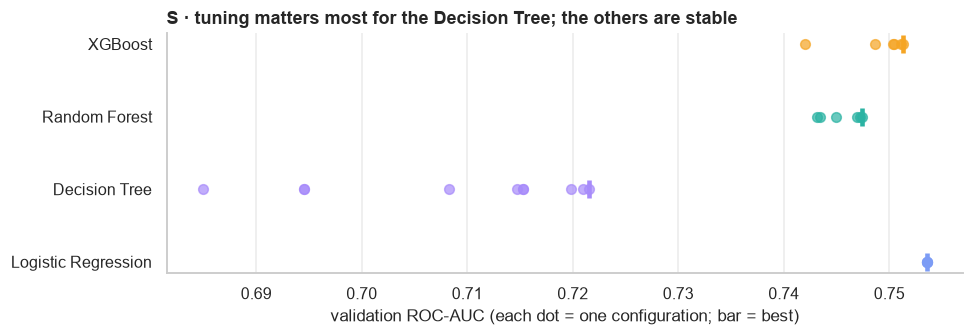

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, m in enumerate(config.MODELS):
    v = tuning_s.loc[tuning_s["model"] == m, "val_roc_auc"]
    ax.scatter(v, [i] * len(v), color=MODEL_COLORS[m], s=40, alpha=0.7)
    ax.scatter(v.max(), i, color=MODEL_COLORS[m], s=140, marker="|", lw=3)
ax.set_yticks(range(4), [NICE[m] for m in config.MODELS])
ax.set_xlabel("validation ROC-AUC (each dot = one configuration; bar = best)")
ax.set_title("S · tuning matters most for the Decision Tree; the others are stable")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "05_s_tuning")
plt.show()

## 5. Dataset S: main results
4 models × 2 class-weight settings × 5 seeds = 40 fits. Every fit records validation and test metrics at the
default 0.5 threshold and at the validation-tuned threshold.

In [6]:
metrics_s, proba_s = M.run_experiment(s, "S_full", M.SPEC_S, best_s)
final_s = M.choose_final(metrics_s)
final_s

,experiment,model,class_weight,val_f1,threshold
0,S_full,decision_tree,balanced,0.421,0.550
1,S_full,logistic_regression,balanced,0.447,0.552
2,S_full,random_forest,balanced,0.442,0.514
3,S_full,xgboost,none,0.445,0.214


`choose_final` picks, for each model, the class-weight setting with the best **validation** F1 at its tuned
threshold. The table below shows the **test** results of those final configurations:

In [7]:
def final_rows(metrics, final):
    key = ["experiment", "model", "class_weight"]
    return metrics.merge(final[key], on=key)

summary_s = ev.summarize(final_rows(metrics_s, final_s), by=("experiment", "model", "class_weight", "threshold_type"))
tbl_s = ev.format_mean_std(summary_s.query("threshold_type == 'tuned'"))
tbl_s["model"] = tbl_s["model"].map(NICE)
tbl_s.drop(columns=["experiment", "threshold_type"]).set_index("model")

,class_weight,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Decision Tree,balanced,0.700 ± 0.012,0.322 ± 0.008,0.591 ± 0.020,0.416 ± 0.005,0.718 ± 0.004,0.353 ± 0.004
Logistic Regression,balanced,0.723 ± 0.011,0.350 ± 0.009,0.612 ± 0.023,0.445 ± 0.005,0.750 ± 0.004,0.403 ± 0.005
Random Forest,balanced,0.720 ± 0.014,0.345 ± 0.011,0.602 ± 0.025,0.438 ± 0.006,0.745 ± 0.004,0.395 ± 0.005
XGBoost,none,0.721 ± 0.012,0.347 ± 0.010,0.610 ± 0.022,0.442 ± 0.005,0.748 ± 0.004,0.401 ± 0.004


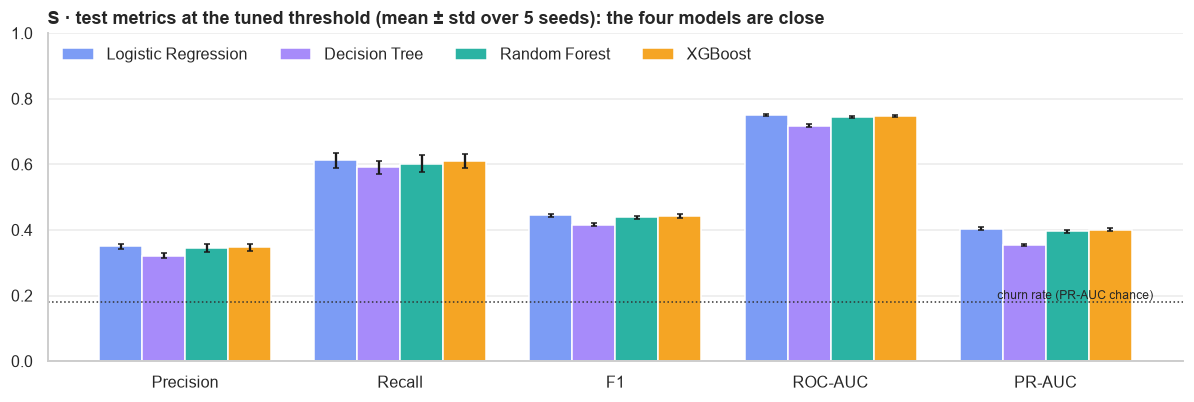

In [8]:
def grouped_bars(summary, title, fname, metrics=("precision", "recall", "f1", "roc_auc", "pr_auc"), ref=None):
    sm = summary.query("threshold_type == 'tuned'").set_index("model")
    fig, ax = plt.subplots(figsize=(11, 3.8))
    w = 0.2
    x = np.arange(len(metrics))
    for i, m in enumerate(config.MODELS):
        means = [sm.loc[m, f"{k}_mean"] for k in metrics]
        stds = [sm.loc[m, f"{k}_std"] for k in metrics]
        ax.bar(x + (i - 1.5) * w, means, w, yerr=stds, capsize=2, color=MODEL_COLORS[m], label=NICE[m])
    if ref is not None:
        ax.axhline(ref, color="#333", ls=":", lw=1)
        ax.text(len(metrics) - 0.5, ref, " churn rate (PR-AUC chance)", fontsize=8, va="bottom", ha="right")
    ax.set_xticks(x, [k.replace("_", "-").upper() if "auc" in k else k.capitalize() for k in metrics])
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(ncol=4, loc="upper left")
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()

grouped_bars(summary_s, "S · test metrics at the tuned threshold (mean ± std over 5 seeds): the four models are close",
             "05_s_model_comparison", ref=s[TARGET].mean())

## 6. Class weighting vs threshold tuning (S)

Two common responses to imbalance:
* **Class weighting** makes errors on churners cost more during training.
* **Threshold tuning** keeps the model as it is, but flags a customer as a churner at a probability below 0.5.

Do they actually differ?

In [9]:
m = metrics_s[metrics_s["split"] == "test"]
cmp = (m.groupby(["model", "class_weight", "threshold_type"])[["threshold", "precision", "recall", "f1", "roc_auc"]]
        .mean().reset_index())
cmp["model"] = cmp["model"].map(NICE)
cmp.set_index(["model", "class_weight", "threshold_type"])

threshold  precision  recall  \
model               class_weight threshold_type                                 
Decision Tree       balanced     default             0.500      0.296   0.681   
                                 tuned               0.550      0.322   0.591   
                    none         default             0.500      0.507   0.089   
                                 tuned               0.214      0.325   0.575   
Logistic Regression balanced     default             0.500      0.320   0.691   
                                 tuned               0.552      0.350   0.612   
                    none         default             0.500      0.574   0.115   
                                 tuned               0.222      0.355   0.592   
Random Forest       balanced     default             0.500      0.334   0.633   
                                 tuned               0.514      0.345   0.602   
                    none         default             0.500      0.662   0.028   
                                 tuned               0.218      0.347   0.598   
XGBoost             balanced     default             0.500      0.318   0.695   
                                 tuned               0.548      0.345   0.615   
                    none         default             0.500      0.586   0.096   
                                 tuned               0.214      0.347   0.610   

                                                   f1  roc_auc  
model               class_weight threshold_type                 
Decision Tree       balanced     default        0.412    0.718  
                                 tuned          0.416    0.718  
                    none         default        0.152    0.718  
                                 tuned          0.414    0.718  
Logistic Regression balanced     default        0.438    0.750  
                                 tuned          0.445    0.750  
                    none         default        0.191    0.750  
                                 tuned          0.444    0.750  
Random Forest       balanced     default        0.437    0.745  
                                 tuned          0.438    0.745  
                    none         default        0.054    0.745  
                                 tuned          0.438    0.745  
XGBoost             balanced     default        0.436    0.748  
                                 tuned          0.442    0.748  
                    none         default        0.164    0.748  
                                 tuned          0.442    0.748

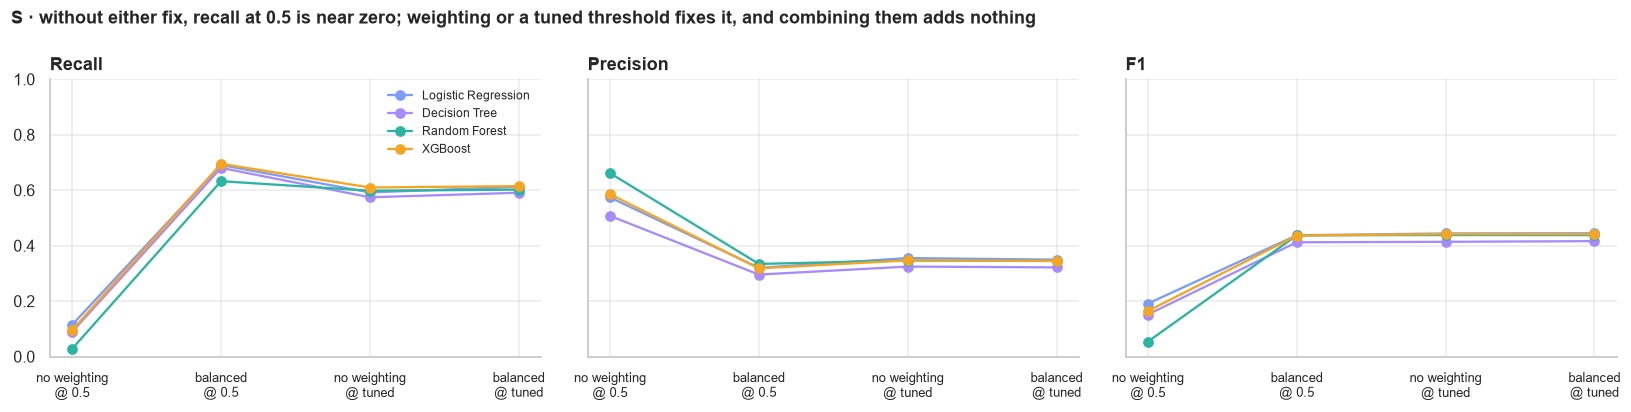

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
setups = [("none", "default"), ("balanced", "default"), ("none", "tuned"), ("balanced", "tuned")]
labels = ["no weighting\n@ 0.5", "balanced\n@ 0.5", "no weighting\n@ tuned", "balanced\n@ tuned"]
for ax, metric in zip(axes, ["recall", "precision", "f1"]):
    for i, mdl in enumerate(config.MODELS):
        vals = [m[(m["model"] == mdl) & (m["class_weight"] == cw) & (m["threshold_type"] == tt)][metric].mean()
                for cw, tt in setups]
        ax.plot(range(4), vals, marker="o", color=MODEL_COLORS[mdl], label=NICE[mdl])
    ax.set_xticks(range(4), labels, fontsize=8.5)
    ax.set_title(metric.capitalize())
    ax.set_ylim(0, 1)
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("S · without either fix, recall at 0.5 is near zero; weighting or a tuned threshold fixes it, "
             "and combining them adds nothing", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "05_s_weighting_vs_threshold")
plt.show()

* With **no weighting at 0.5**, the models predict "stays" for almost everyone: very low recall, the
  accuracy trap from section 2.
* **Balanced weights** push the predicted probabilities up, so 0.5 becomes a reasonable cut-off and recall jumps.
* **Tuning the threshold** reaches about the same F1 with or without weighting. Weighting mostly *moves*
  probabilities rather than improving the ranking, which is why ROC-AUC barely changes between settings.
* Practical takeaway: on S, **always tune the decision threshold**. Class weighting is optional.

## 7. Final models, threshold curve and ROC / PR curves (S)
The chosen configurations are saved to `reports/results/final_models.json` and refitted on the seed-0 training
split (`models/S_full__<model>.joblib`). The app and notebook 06 (interpretation) load these files.

In [11]:
specs = {"S_full": M.SPEC_S, "A_full": M.SPEC_A}
M.save_final_config(final_s, {"S_full": best_s}, specs)
fitted_s = M.fit_final_models("S_full", s, seed=0)
cfg_s = M.load_final_config()["S_full"]["models"]
pd.DataFrame(cfg_s).T

,class_weight,threshold,val_f1,params
decision_tree,balanced,0.550,0.421,"{'max_depth': 8, 'min_samples_leaf': 100}"
logistic_regression,balanced,0.550,0.447,{'C': 0.01}
random_forest,balanced,0.510,0.442,"{'n_estimators': 300, 'max_depth': 16, 'min_sa..."
xgboost,none,0.210,0.445,"{'n_estimators': 400, 'learning_rate': 0.03, '..."


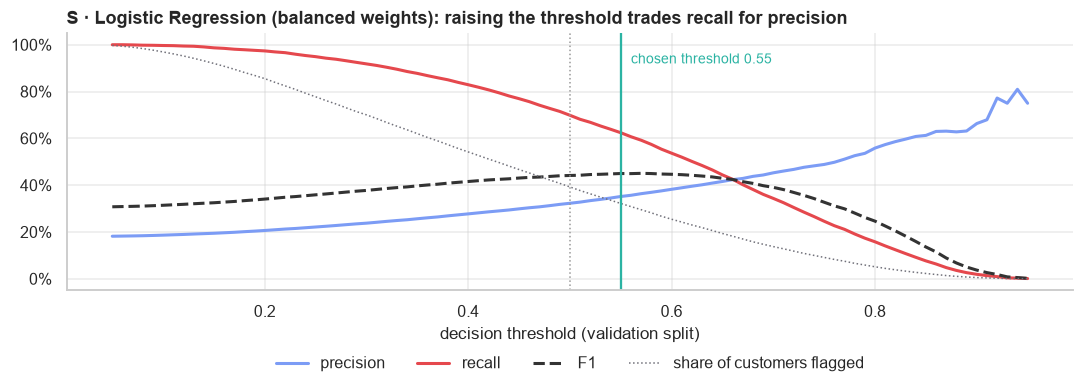

In [12]:
best_model_s = max(cfg_s, key=lambda k: cfg_s[k]["val_f1"])
p_val = fitted_s[best_model_s].predict_proba(val_s[M.SPEC_S.columns])[:, 1]
curve = ev.threshold_curve(val_s[TARGET], p_val)
t_star = cfg_s[best_model_s]["threshold"]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(curve["threshold"], curve["precision"], color="#7C9CF5", lw=2, label="precision")
ax.plot(curve["threshold"], curve["recall"], color=CHURN, lw=2, label="recall")
ax.plot(curve["threshold"], curve["f1"], color="#333", lw=2, ls="--", label="F1")
ax.plot(curve["threshold"], curve["share_flagged"], color=NEUTRAL, lw=1, ls=":", label="share of customers flagged")
ax.axvline(t_star, color=RETAINED, lw=1.5)
ax.text(t_star + 0.01, 0.92, f"chosen threshold {t_star:.2f}", color=RETAINED, fontsize=9)
ax.axvline(0.5, color="#999", lw=1, ls=":")
ax.set_xlabel("decision threshold (validation split)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(f"S · {NICE[best_model_s]} ({cfg_s[best_model_s]['class_weight']} weights): "
             "raising the threshold trades recall for precision")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
savefig(fig, "05_s_threshold_curve")
plt.show()

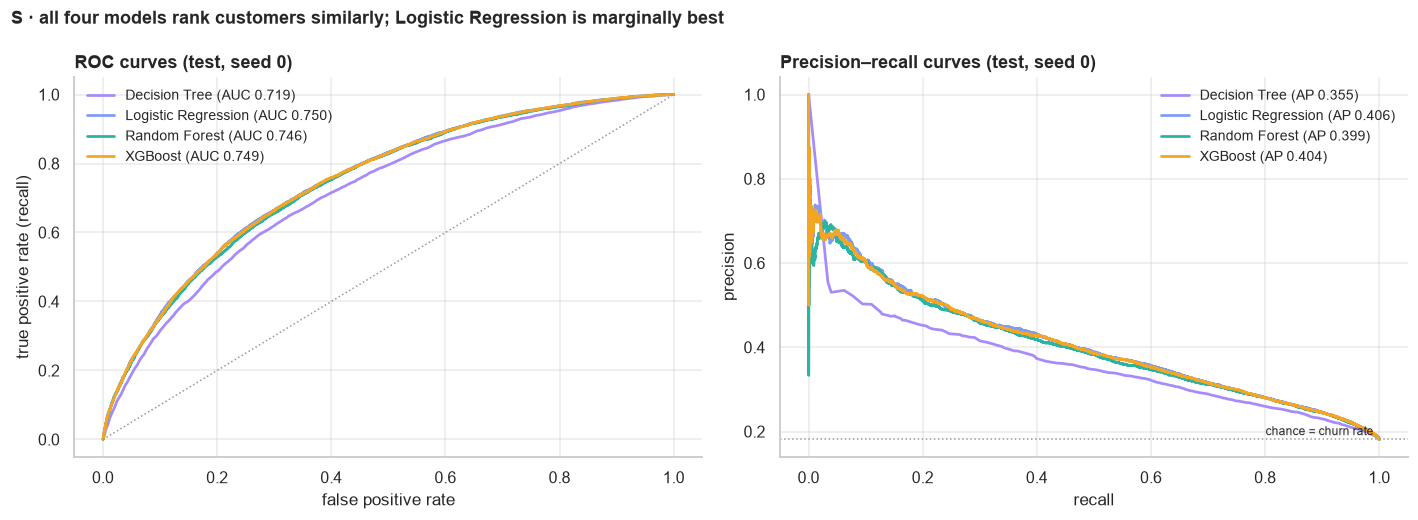

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
y_test = test_s[TARGET].to_numpy()
for mdl, pipe in fitted_s.items():
    p = pipe.predict_proba(test_s[M.SPEC_S.columns])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    met = ev.metrics_from_proba(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[mdl], lw=1.8, label=f"{NICE[mdl]} (AUC {met['roc_auc']:.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[mdl], lw=1.8, label=f"{NICE[mdl]} (AP {met['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color="#999", ls=":", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curves (test, seed 0)")
axes[1].axhline(y_test.mean(), color="#999", ls=":", lw=1)
axes[1].text(0.99, y_test.mean() + 0.01, "chance = churn rate", ha="right", fontsize=8)
axes[1].set(xlabel="recall", ylabel="precision", title="Precision–recall curves (test, seed 0)")
for ax in axes:
    ax.legend(loc="best", fontsize=9)
fig.suptitle("S · all four models rank customers similarly; Logistic Regression is marginally best",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "05_s_roc_pr_curves")
plt.show()

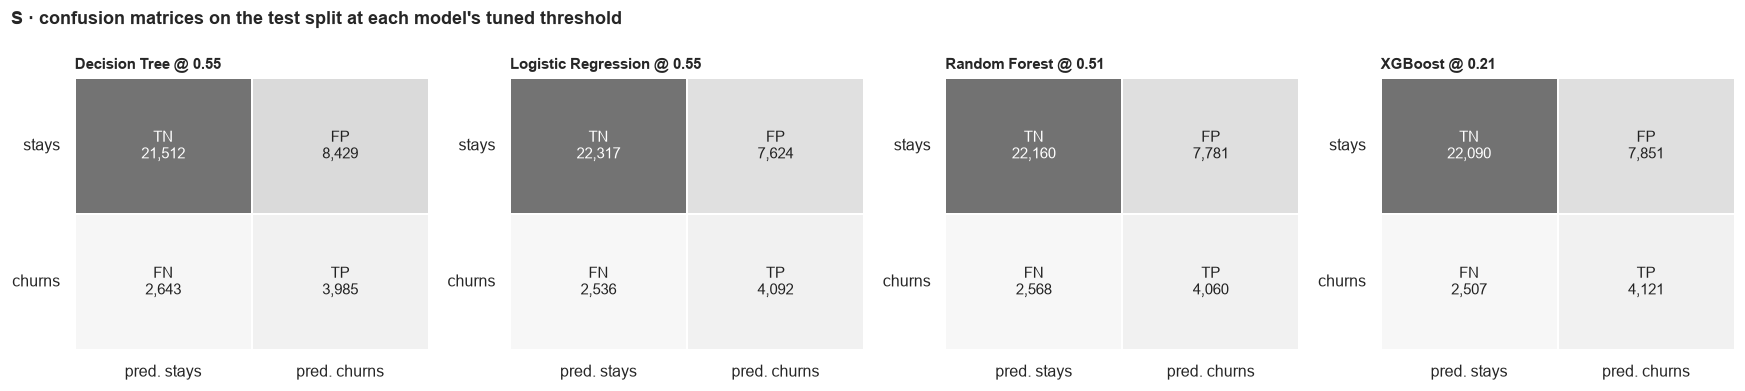

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (mdl, pipe) in zip(axes, fitted_s.items()):
    t = cfg_s[mdl]["threshold"]
    p = pipe.predict_proba(test_s[M.SPEC_S.columns])[:, 1]
    c = ev.confusion(y_test, p, t)
    mat = np.array([[c["tn"], c["fp"]], [c["fn"], c["tp"]]])
    sns.heatmap(mat, annot=False, cmap="Greys", cbar=False, ax=ax, vmin=0, vmax=mat.max() * 1.6, linewidths=1)
    for (i, j), lab in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ["TN", "FP", "FN", "TP"]):
        ax.text(j + 0.5, i + 0.5, f"{lab}\n{mat[i, j]:,}", ha="center", va="center", fontsize=10,
                color="white" if mat[i, j] > mat.max() * 0.8 else "#222")
    ax.set_xticklabels(["pred. stays", "pred. churns"])
    ax.set_yticklabels(["stays", "churns"], rotation=0)
    ax.set_title(f"{NICE[mdl]} @ {t:.2f}", fontsize=10)
fig.suptitle("S · confusion matrices on the test split at each model's tuned threshold",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "05_s_confusion_matrices")
plt.show()

## 8. Dataset A: the same protocol
A is small (5,000) and balanced, so class weighting hardly matters. Notebook 01 predicted near-perfect separation.

In [15]:
tuning_a, best_a = M.tune(a, M.SPEC_A, seed=0)
tuning_a["experiment"] = "A_full"
metrics_a, proba_a = M.run_experiment(a, "A_full", M.SPEC_A, best_a)
final_a = M.choose_final(metrics_a)
M.save_final_config(final_a, {"A_full": best_a}, specs)
fitted_a = M.fit_final_models("A_full", a, seed=0)

summary_a = ev.summarize(final_rows(metrics_a, final_a))
tbl_a = ev.format_mean_std(summary_a.query("threshold_type == 'tuned'"))
tbl_a["model"] = tbl_a["model"].map(NICE)
tbl_a.drop(columns=["experiment", "threshold_type"]).set_index("model")

,class_weight,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Decision Tree,balanced,0.962 ± 0.008,0.965 ± 0.007,0.959 ± 0.020,0.962 ± 0.008,0.991 ± 0.004,0.988 ± 0.004
Logistic Regression,balanced,0.886 ± 0.008,0.860 ± 0.027,0.925 ± 0.025,0.891 ± 0.005,0.963 ± 0.002,0.964 ± 0.003
Random Forest,balanced,0.967 ± 0.003,0.970 ± 0.006,0.966 ± 0.004,0.968 ± 0.003,0.995 ± 0.001,0.996 ± 0.001
XGBoost,balanced,0.982 ± 0.006,0.979 ± 0.006,0.985 ± 0.009,0.982 ± 0.006,0.999 ± 0.001,0.999 ± 0.001


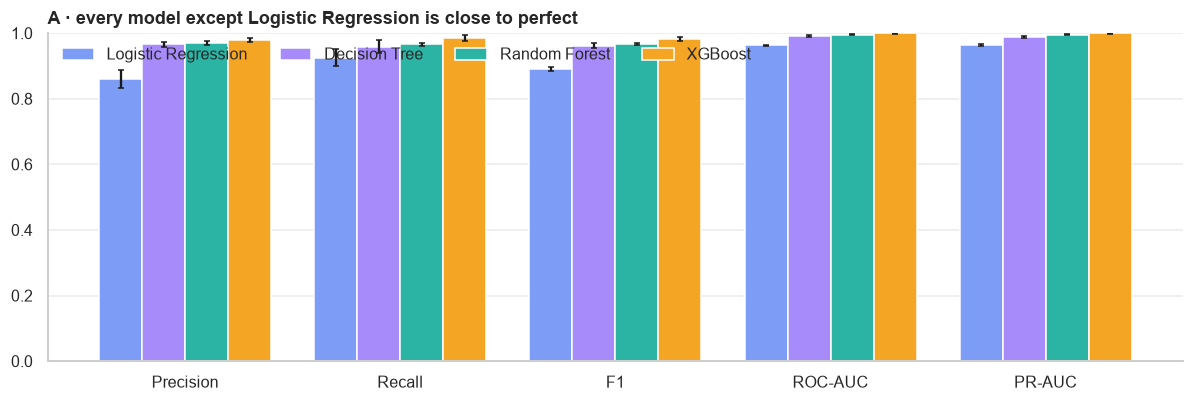

In [16]:
grouped_bars(summary_a, "A · every model except Logistic Regression is close to perfect", "05_a_model_comparison")

Logistic Regression is the weakest model on A because A's main signal is a **step** (churn jumps after 30 days
without logging in), which a linear model can only approximate. Trees capture the step directly.

## 9. S vs A

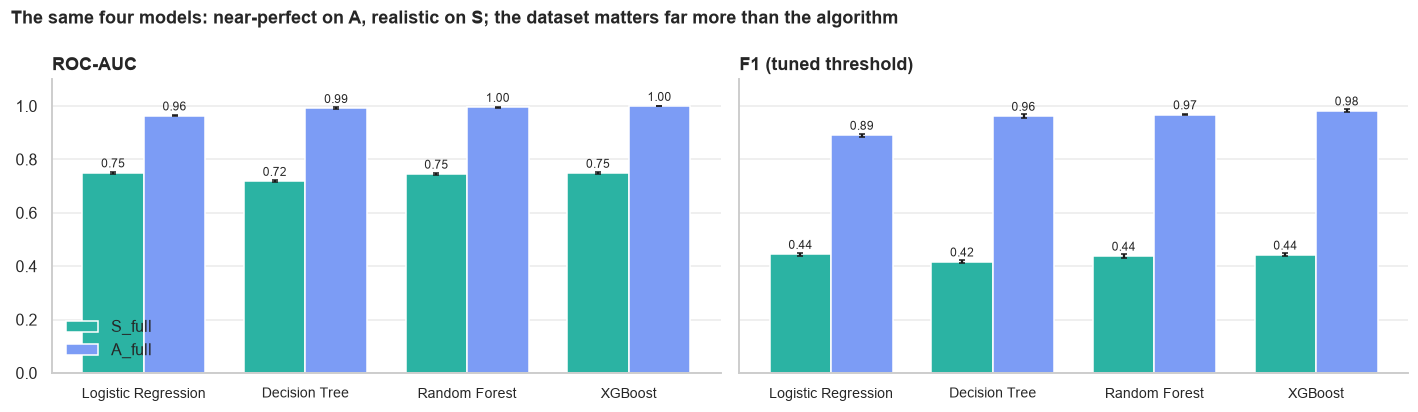

In [17]:
both = pd.concat([summary_s, summary_a]).query("threshold_type == 'tuned'")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, metric in zip(axes, ["roc_auc", "f1"]):
    for i, mdl in enumerate(config.MODELS):
        for j, (exp, col) in enumerate([("S_full", "#2BB3A3"), ("A_full", "#7C9CF5")]):
            r = both[(both["model"] == mdl) & (both["experiment"] == exp)].iloc[0]
            ax.bar(i + (j - 0.5) * 0.38, r[f"{metric}_mean"], 0.38, yerr=r[f"{metric}_std"], capsize=2, color=col,
                   label=exp if i == 0 else None)
            ax.text(i + (j - 0.5) * 0.38, r[f"{metric}_mean"] + 0.02, f"{r[f'{metric}_mean']:.2f}", ha="center", fontsize=8)
    ax.set_xticks(range(4), [NICE[m] for m in config.MODELS], fontsize=9)
    ax.set_title(metric.replace("_", "-").upper() if "auc" in metric else "F1 (tuned threshold)")
    ax.set_ylim(0, 1.1)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="lower left")
fig.suptitle("The same four models: near-perfect on A, realistic on S; the dataset matters far more than the algorithm",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "05_s_vs_a")
plt.show()

## 10. Augmentation study experiments (`A_hard`, `A_hard_augmented`, `A_hard_random`)

These datasets are produced by **notebook 04 (Sukhraj)** in `data/processed/`. When they exist, this section
trains the same four models on them with the same protocol, so the results go straight into `metrics.csv`. Until
then it is skipped.

Each file must contain `customer_id`, `churned`, the A_hard columns, and (for the augmented and random
versions) the transferred columns, whose names are listed in `features.TRANSFER_FEATURES`.

In [18]:
hard_names = ["A_hard", "A_hard_augmented", "A_hard_random"]
available = [n for n in hard_names if config.experiment_path(n).exists()]
metrics_hard, proba_hard = [], []
if len(available) < len(hard_names):
    print("Skipped: waiting for notebook 04. Missing:", [n for n in hard_names if n not in available])
else:
    from churn import features
    for name in hard_names:
        df = data.load_experiment(name)
        spec = M.SPEC_A_HARD
        if name != "A_hard":
            extra = [c for c in features.TRANSFER_FEATURES if c in df.columns]
            num = [c for c in extra if pd.api.types.is_numeric_dtype(df[c])]
            spec = spec.add(numeric=num, categorical=[c for c in extra if c not in num])
        _, best = M.tune(df, spec, seed=0)
        met, prb = M.run_experiment(df, name, spec, best)
        fin = M.choose_final(met)
        specs[name] = spec
        M.save_final_config(fin, {name: best}, specs)
        metrics_hard.append(met)
        proba_hard.append(prb)
    hard_summary = ev.summarize(pd.concat(metrics_hard).query("class_weight == 'none'"))
    display(ev.format_mean_std(hard_summary.query("threshold_type == 'tuned'")))

Skipped: waiting for notebook 04. Missing: ['A_hard', 'A_hard_augmented', 'A_hard_random']


## Save results

In [19]:
new_metrics = pd.concat([metrics_s, metrics_a, *metrics_hard], ignore_index=True)
new_tuning = pd.concat([tuning_s, tuning_a], ignore_index=True)

finals = M.load_final_config()
pred_parts = []
for prb in [proba_s, proba_a, *proba_hard]:
    exp = prb["experiment"].iloc[0]
    chosen = {m: v["class_weight"] for m, v in finals[exp]["models"].items()}
    pred_parts.append(prb[prb["class_weight"] == prb["model"].map(chosen)])
new_preds = pd.concat(pred_parts, ignore_index=True)

def upsert(path, new):
    # Replace the rows of the experiments we just ran, keep the others (e.g. from a later run)
    if path.exists():
        old = pd.read_csv(path)
        new = pd.concat([old[~old["experiment"].isin(new["experiment"].unique())], new], ignore_index=True)
    new.to_csv(path, index=False)
    return path

for path, df in [(config.RESULTS_DIR / "metrics.csv", new_metrics),
                 (config.RESULTS_DIR / "predictions.csv", new_preds),
                 (config.RESULTS_DIR / "tuning.csv", new_tuning)]:
    p = upsert(path, df)
    print(f"{p.relative_to(config.ROOT)}  {p.stat().st_size / 1e6:.1f} MB")
print("final_models.json experiments:", list(M.load_final_config()))

reports\results\metrics.csv  0.1 MB


reports\results\predictions.csv  9.4 MB
reports\results\tuning.csv  0.0 MB
final_models.json experiments: ['S_full', 'A_full']


## 11. Key findings

**Dataset S, the main result** (test split, mean ± std over 5 seeds, tuned threshold)

| Model | ROC-AUC | PR-AUC | F1 | Recall | Precision |
|---|---|---|---|---|---|
| **Logistic Regression** | **0.750 ± 0.004** | **0.403** | **0.445** | 0.61 | 0.35 |
| XGBoost | 0.748 ± 0.004 | 0.401 | 0.442 | 0.61 | 0.35 |
| Random Forest | 0.745 ± 0.004 | 0.395 | 0.438 | 0.60 | 0.35 |
| Decision Tree | 0.718 ± 0.004 | 0.353 | 0.416 | 0.59 | 0.32 |

1. **Logistic Regression is (marginally) the best model on S**, ahead of XGBoost and Random Forest. Its lead over
   them is about one standard deviation, so in practice the top three are tied. The Decision Tree is clearly
   weakest. A simple linear model wins because S's columns are independent of each other and each has a
   smooth, one-directional effect on churn (notebook 01), so there are no interactions for the tree ensembles
   to exploit. This matches the literature review: **no classifier is universally best**, so the data decides.
2. **What the numbers mean in practice:** at the tuned threshold the models catch **about 6 in 10 churners**,
   and **about 1 in 3 flagged customers really churns**. That is roughly double the 18% base rate, which is
   useful for targeting a retention offer, though far from perfect.
3. **Imbalance:** with no weighting at a 0.5 threshold, recall collapses to 3–12% (the accuracy trap: a do-nothing
   model already scores 81.9%). Either **balanced class weights** or a **validation-tuned threshold** fixes this,
   and **combining them adds nothing**. ROC-AUC is identical across all settings, because weighting shifts the
   probabilities but does not improve the ranking.

**Dataset A**

4. Near-perfect: XGBoost reaches ROC-AUC **0.999** and F1 **0.982**. Logistic Regression is the weakest model
   (ROC-AUC 0.963, F1 0.891) because A's main signal is a step (the 30-day login cliff), which trees capture and
   a linear model cannot.
5. **The dataset matters far more than the algorithm.** The same four models span 0.72–0.75 ROC-AUC on S and
   0.96–0.999 on A, and the best model differs between the two datasets.

---

### Implications for the next phases
* **Saved artifacts:**
  - `reports/results/metrics.csv`, `predictions.csv` (test split, seed 0, final configuration), `tuning.csv`
  - `final_models.json` (parameters, class weight and tuned threshold per model)
  - `models/{S_full,A_full}__*.joblib`. Regenerate these with `python -m churn.models`.
* **Notebook 06, interpretation (Sukhraj):**
  - Logistic Regression's coefficients are directly interpretable, and they are the best model on S.
  - Pair them with XGBoost + SHAP to check the drivers agree.
  - Most final S models use **balanced** weights, so their outputs are **scores, not calibrated probabilities**
    (they are pushed upward). For risk tiers and the predictor's "churn probability", either use a
    `class_weight="none"` model or define tiers by quantile or threshold rather than fixed 0.3/0.6 cut-offs.
* **App (Aayush):**
  - The Model comparison page reads `metrics.csv`.
  - The Budget simulator can use `predictions.csv` (y_true + proba) directly.
* **Section 10** runs automatically once notebook 04 writes `data/processed/A_hard*.csv`.